# Krylov Subspace Methods for Solving Linear Systems

## Numerical Implementations and Convergence Analysis

This notebook presents a numerical study of iterative methods for
solving linear systems of the form

$$
Ax=b,
$$

where

$$
A\in\mathbb{R}^{n\times n},
\qquad
b\in\mathbb{R}^{n}.
$$

We investigate five algorithms:

1. Steepest Descent
2. Conjugate Gradient (CG)
3. Generalized Minimal Residual (GMRES)
4. Bi-Conjugate Gradient Stabilized (BiCGSTAB)
5. Symmetric Lanczos

The numerical experiments examine:

- Convergence of residual norms.
- Accuracy of computed solutions.
- Number of iterations.
- Performance on symmetric and nonsymmetric systems.
- Lanczos tridiagonalization and Ritz values.

All numerical algorithms are implemented in separate Python modules
and imported into this notebook.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Locate the repository root.
current = Path.cwd().resolve()

repo_root = next(
    (
        path
        for path in (current, *current.parents)
        if (path / "krylov_methods" / "gmres.py").is_file()
    ),
    None,
)

if repo_root is None:
    raise RuntimeError(
        "Cannot locate the repository root."
    )

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

#print("Repository:", repo_root)
#print("NumPy:", np.__version__)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from krylov_methods.steepest_descent import steepest_descent
from krylov_methods.conjugate_gradient import conjugate_gradient
from krylov_methods.gmres import gmres
from krylov_methods.bicgstab import bicgstab
from krylov_methods.symmetric_lanczos import symmetric_lanczos
from krylov_methods.visualization.plot_convergence import (
    plot_convergence,
    plot_krylov_comparison,
)
from krylov_methods.visualization.plot_lanczos import (
    plot_ritz_values,
)

## 1. Convergence on a Symmetric Positive-Definite System

We consider the linear system $Ax=b,$ where $A$ is symmetric positive definite (SPD).

For this class of matrices, Steepest Descent and Conjugate Gradient
are guaranteed to converge in exact arithmetic.

Conjugate Gradient generally converges faster because it constructs
mutually $A$-conjugate search directions.

GMRES and BiCGSTAB can also solve SPD systems, although they are
designed for more general matrices.

The convergence criterion is

$$
\|b-Ax_k\|_2 \leq 10^{-10}.
$$

In [3]:
# ============================================================
# Experiment 1: Symmetric positive-definite system
# ============================================================

n = 30

A = (
    2.0 * np.eye(n)
    - np.eye(n, k=1)
    - np.eye(n, k=-1)
)

b = np.ones(n)
x0 = np.zeros(n)

tol = 1e-10
max_iter = 10000

# Reference solution
x_exact = np.linalg.solve(A, b)

print("=" * 55)
print("SYMMETRIC POSITIVE-DEFINITE TEST PROBLEM")
print("=" * 55)

print("Matrix dimension:", n)
print("Symmetric:", np.allclose(A, A.T))

eigenvalues = np.linalg.eigvalsh(A)

print("Minimum eigenvalue:", eigenvalues.min())
print("Maximum eigenvalue:", eigenvalues.max())
print("Condition number:", np.linalg.cond(A))

SYMMETRIC POSITIVE-DEFINITE TEST PROBLEM
Matrix dimension: 30
Symmetric: True
Minimum eigenvalue: 0.010261353216209655
Maximum eigenvalue: 3.98973864678379
Condition number: 388.8121344932614


In [4]:
# ============================================================
# Run the four iterative solvers
# ============================================================

results = {}

algorithms = {
    "Steepest Descent": steepest_descent,
    "Conjugate Gradient": conjugate_gradient,
    "GMRES": gmres,
    "BiCGSTAB": bicgstab,
}

for name, solver in algorithms.items():

    result = solver(
        A,
        b,
        x0=x0,
        tol=tol,
        max_iter=max_iter,
    )

    results[name] = result

    error = np.linalg.norm(
        result["solution"] - x_exact
    )

    print(f"\n{name}")
    print("-" * 40)
    print("Converged:", result["converged"])
    print("Iterations:", result["iterations"])
    print("Solution error:", f"{error:.3e}")
    print(
        "Final residual:",
        f"{result['residual_norms'][-1]:.3e}",
    )


Steepest Descent
----------------------------------------
Converged: True
Iterations: 4806
Solution error: 6.909e-09
Final residual: 9.953e-11

Conjugate Gradient
----------------------------------------
Converged: True
Iterations: 15
Solution error: 1.154e-12
Final residual: 0.000e+00

GMRES
----------------------------------------
Converged: True
Iterations: 15
Solution error: 7.024e-12
Final residual: 2.443e-13

BiCGSTAB
----------------------------------------
Converged: True
Iterations: 15
Solution error: 6.231e-11
Final residual: 4.257e-12


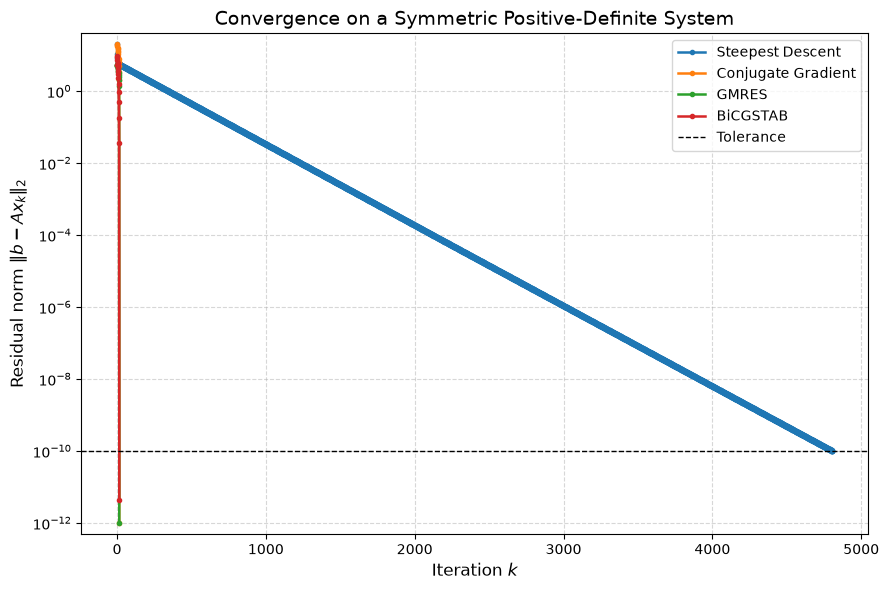

In [5]:
# ============================================================
# Residual convergence comparison
# ============================================================

fig, ax = plot_convergence(
    results,
    tol=tol,
    title="Convergence on a Symmetric Positive-Definite System",
)

plt.show()

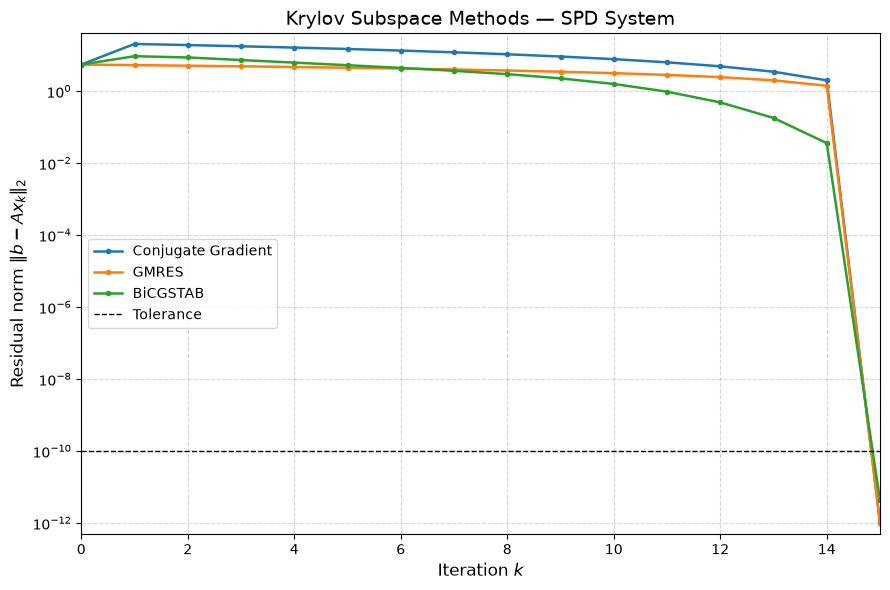

In [6]:
fig, ax = plot_krylov_comparison(
    results,
    tol=tol,
    title="Krylov Subspace Methods — SPD System",
)

plt.show()

### Numerical observations

**Steepest Descent:** exhibits slow convergence for the considered SPD system. Its convergence rate depends strongly on the condition number of the coefficient matrix.

**Conjugate Gradient:** converges significantly faster by constructing mutually conjugate search directions.

**GMRES:** GMRES minimizes the residual norm over successive Krylov subspaces and achieves high numerical accuracy.

**BiCGSTAB:** converges rapidly for this experiment. Unlike GMRES, its residual convergence is not necessarily monotonic.

---

## 2. Convergence on a Nonsymmetric Linear System

We now consider a linear system $Ax=b,$ where $A$ is nonsymmetric.

Unlike Conjugate Gradient, GMRES and BiCGSTAB do not require
the coefficient matrix to be symmetric positive definite.


In [7]:
# ============================================================
# Experiment 2: Nonsymmetric convection-diffusion system
# ============================================================

n = 60

epsilon = 0.1
c = 1.0

h = 1.0 / (n + 1)

main = 2.0 * epsilon / h**2

lower = -epsilon / h**2 - c / (2.0 * h)
upper = -epsilon / h**2 + c / (2.0 * h)

A_ns = (
    main * np.eye(n)
    + lower * np.eye(n, k=-1)
    + upper * np.eye(n, k=1)
)

b_ns = np.ones(n)
x0_ns = np.zeros(n)

tol_ns = 1e-10
max_iter_ns = 100

x_exact_ns = np.linalg.solve(A_ns, b_ns)

print("=" * 55)
print("NONSYMMETRIC TEST PROBLEM")
print("=" * 55)

print("Matrix dimension:", n)
print("Symmetric:", np.allclose(A_ns, A_ns.T))
print("Condition number:", np.linalg.cond(A_ns))

NONSYMMETRIC TEST PROBLEM
Matrix dimension: 60
Symmetric: False
Condition number: 749.9054554180246


In [8]:
# ============================================================
# GMRES vs BiCGSTAB
# ============================================================

results_ns = {}

algorithms_ns = {
    "GMRES": gmres,
    "BiCGSTAB": bicgstab,
}

for name, solver in algorithms_ns.items():

    result = solver(
        A_ns,
        b_ns,
        x0=x0_ns,
        tol=tol_ns,
        max_iter=max_iter_ns,
    )

    results_ns[name] = result

    error = np.linalg.norm(
        result["solution"] - x_exact_ns
    )

    residual = np.linalg.norm(
        b_ns - A_ns @ result["solution"]
    )

    print(f"\n{name}")
    print("-" * 40)
    print("Converged:", result["converged"])
    print("Iterations:", result["iterations"])
    print("Solution error:", f"{error:.3e}")
    print("Final residual:", f"{residual:.3e}")


GMRES
----------------------------------------
Converged: True
Iterations: 60
Solution error: 3.508e-14
Final residual: 1.991e-12

BiCGSTAB
----------------------------------------
Converged: True
Iterations: 72
Solution error: 1.027e-11
Final residual: 5.155e-11


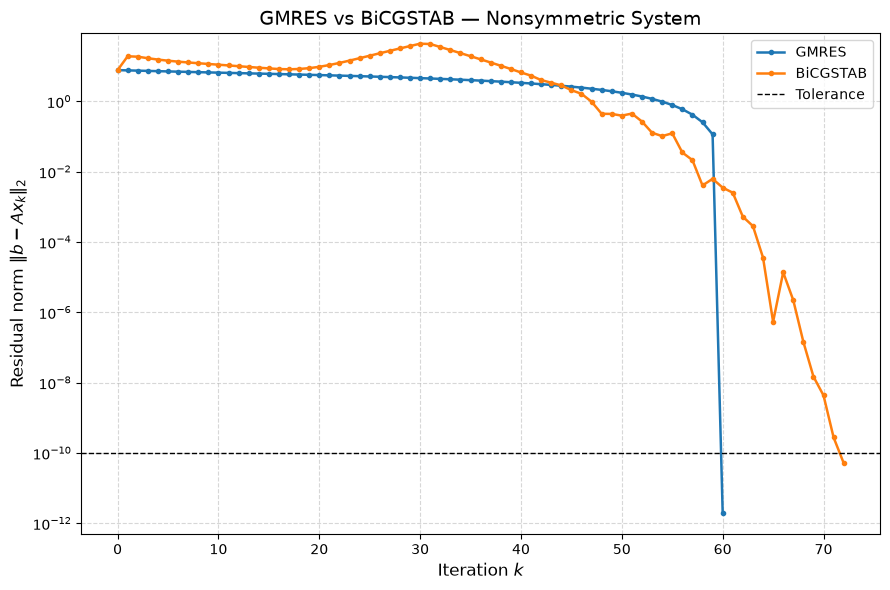

In [9]:
fig, ax = plot_convergence(
    results_ns,
    tol=tol_ns,
    title="GMRES vs BiCGSTAB — Nonsymmetric System",
)

plt.show()

### Numerical observations

GMRES requires fewer iterations for this experiment,
while BiCGSTAB avoids storing an expanding Krylov basis.

**GMRES** 

Its residual norm decreases monotonically, reflecting
the residual-minimization property of the algorithm.

For the considered 60-dimensional system, unrestarted
GMRES achieves convergence within the full Krylov
subspace.

**BiCGSTAB**

The residual history is nonmonotonic, exhibiting
temporary increases before reaching the prescribed
tolerance.

This behavior is consistent with the short-recurrence
structure of BiCGSTAB.


---

## 3. Symmetric Lanczos Algorithm

The Symmetric Lanczos algorithm constructs an orthonormal basis
of the Krylov subspace

$$
\mathcal{K}_m(A,r_0)
=
\operatorname{span}
\{r_0,Ar_0,\ldots,A^{m-1}r_0\},
$$

where $A$ is a symmetric matrix.

The Lanczos recurrence generates a symmetric tridiagonal matrix

$$
T_m = V_m^T A V_m.
$$

The Lanczos relation is

$$
AV_m
=
V_mT_m
+
\beta_m v_{m+1}e_m^T.
$$

The eigenvalues of $T_m$, called **Ritz values**,
provide approximations to eigenvalues of $A$.

### Numerical objectives

We investigate:

- The orthogonality condition $V_m^TV_m\approx I$.
- The structure of the projected matrix $T_m$.
- The approximation of eigenvalues using Ritz values.
- The accuracy of the Galerkin approximation to $Ax=b$.

In [10]:
# ============================================================
# Experiment 3: Symmetric Lanczos
# ============================================================

n_lanczos = 20

A_lanczos = (
    2.0 * np.eye(n_lanczos)
    - np.eye(n_lanczos, k=1)
    - np.eye(n_lanczos, k=-1)
)

rng = np.random.default_rng(42)

b_lanczos = rng.standard_normal(n_lanczos)

x0_lanczos = np.zeros(n_lanczos)

m_lanczos = 12

result_lanczos = symmetric_lanczos(
    A_lanczos,
    b_lanczos,
    x0=x0_lanczos,
    m=m_lanczos,
    tol=1e-12,
)

V = result_lanczos["basis"]
T = result_lanczos["tridiagonal"]

print("=" * 60)
print("SYMMETRIC LANCZOS — NUMERICAL EXPERIMENT")
print("=" * 60)

print("Matrix dimension:", n_lanczos)
print("Lanczos iterations:", result_lanczos["iterations"])
print("Converged:", result_lanczos["converged"])

print("\nLanczos basis shape:", V.shape)
print("Tridiagonal matrix shape:", T.shape)

print(
    "\nOrthogonality error:",
    np.linalg.norm(
        V.T @ V - np.eye(V.shape[1])
    ),
)

print(
    "Projection error:",
    np.linalg.norm(
        V.T @ A_lanczos @ V - T
    ),
)

print(
    "Final residual:",
    np.linalg.norm(
        b_lanczos - A_lanczos @ result_lanczos["solution"]
    ),
)

SYMMETRIC LANCZOS — NUMERICAL EXPERIMENT
Matrix dimension: 20
Lanczos iterations: 12
Converged: False

Lanczos basis shape: (20, 12)
Tridiagonal matrix shape: (12, 12)

Orthogonality error: 1.3348328692120587e-14
Projection error: 1.0410370729796795e-14
Final residual: 0.1508087117340501


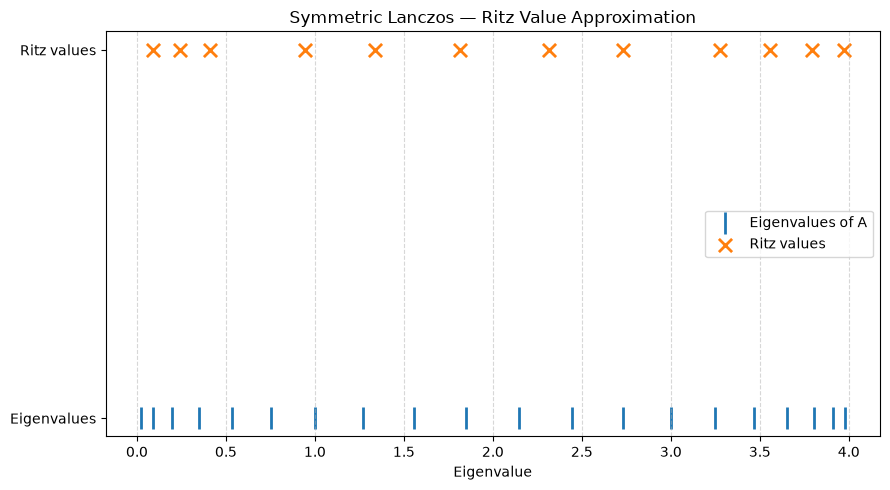

In [11]:
fig, ax = plot_ritz_values(
    A_lanczos,
    result_lanczos,
)

plt.show()

### Numerical observations

The numerical experiment investigates the symmetric Lanczos
algorithm applied to a symmetric positive-definite matrix
of dimension $n=20$.

A Krylov subspace of dimension $m=12$ is constructed.

**Orthogonality of the Lanczos basis**

The numerical results confirm

$$
V_m^TV_m\approx I_m.
$$

The orthogonality error is approximately

$$
\|V_m^TV_m-I_m\|_F
\approx 1.33\times10^{-14}.
$$

This indicates excellent numerical orthogonality for
the considered experiment.

**Tridiagonal projection**

The Lanczos tridiagonal matrix satisfies

$$
T_m\approx V_m^TAV_m.
$$

The projection error is approximately

$$
\|V_m^TAV_m-T_m\|_F
\approx 1.04\times10^{-14}.
$$

**Ritz eigenvalue approximations**

The eigenvalues of $T_m$, called Ritz values, provide
approximations to eigenvalues of the original matrix $A$.

The numerical experiment illustrates how spectral
information can be extracted from a lower-dimensional
Krylov subspace.

**Galerkin approximation**

The approximate solution obtained from the projected
linear system does not reach the prescribed tolerance
after 12 iterations.

This is expected because the Krylov subspace has
dimension $m=12<n=20$.

**Conclusion**

The experiment confirms the fundamental properties
of symmetric Lanczos tridiagonalization and illustrates
its usefulness for spectral approximation.

In [12]:
# ============================================================
# Full-dimensional Lanczos verification
# ============================================================

result_full = symmetric_lanczos(
    A_lanczos,
    b_lanczos,
    x0=x0_lanczos,
    m=n_lanczos,
    tol=1e-10,
)

x_exact = np.linalg.solve(
    A_lanczos,
    b_lanczos,
)

print("=" * 60)
print("FULL-DIMENSIONAL LANCZOS VERIFICATION")
print("=" * 60)

print("Converged:", result_full["converged"])
print("Iterations:", result_full["iterations"])

print(
    "Final residual:",
    np.linalg.norm(
        b_lanczos - A_lanczos @ result_full["solution"]
    ),
)

print(
    "Solution error:",
    np.linalg.norm(
        result_full["solution"] - x_exact
    ),
)

print(
    "Orthogonality error:",
    np.linalg.norm(
        result_full["basis"].T @ result_full["basis"]
        - np.eye(result_full["iterations"])
    ),
)

FULL-DIMENSIONAL LANCZOS VERIFICATION
Converged: True
Iterations: 20
Final residual: 5.542061156609153e-15
Solution error: 9.749123710748974e-15
Orthogonality error: 3.048646087195979e-14
